# 01 · Análisis exploratorio (EDA) — HU-02

**Objetivo:** entender el dataset *Diabetes 130-US Hospitals* (UCI) antes de decidir qué limpiar:
dimensiones, faltantes (codificados como `"?"`), la variable objetivo, pacientes repetidos y
relación de algunas variables con el reingreso `<30` días.

> Este notebook **solo explora**; ninguna decisión de modelado se toma con el conjunto de test.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data import EXCLUDED_DISCHARGE_IDS, filter_encounters, load_raw

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
raw = load_raw()
print("Filas x columnas:", raw.shape)
raw.head()

Filas x columnas: (101766, 50)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1. Dimensiones y tipos
Se lee con `na_values="?"` y `keep_default_na=False` (para no convertir el texto `"None"` de
`A1Cresult`/`max_glu_serum` en NaN: ahí significa *no medido*, que es información clínica).

In [2]:
raw.dtypes.value_counts()

str      37
int64    13
Name: count, dtype: int64

## 2. Valores faltantes
`weight` (~97 %), `payer_code` (~40 %) y `medical_specialty` (~49 %) concentran los faltantes.

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02

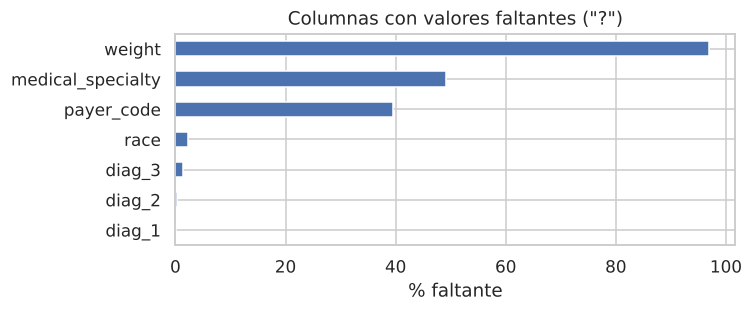

In [3]:
miss = raw.isna().mean().mul(100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
print(miss.to_string())
fig, ax = plt.subplots(figsize=(7, 3))
miss.plot.barh(ax=ax, color="#4c72b0")
ax.set_xlabel("% faltante")
ax.set_title("Columnas con valores faltantes (\"?\")")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG + "eda_faltantes.png", dpi=130)

**Decisión:** `weight` y `payer_code` se eliminan (error 11 del plan). `medical_specialty` se
conserva: se agrupa en las 10 más frecuentes + `Unknown` + `Otra`. `race` (~2 %) se imputa con
la moda *dentro del Pipeline*.

## 3. Variable objetivo
`readmitted` tiene 3 clases (`<30`, `>30`, `NO`). El problema es binario: `target = (readmitted == "<30")`.

readmitted
NO     54864
>30    35545
<30    11357

% <30 en el CSV completo: 11.16

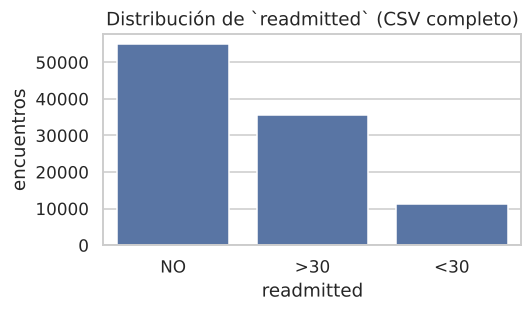

In [4]:
counts = raw["readmitted"].value_counts()
print(counts.to_string())
print("\n% <30 en el CSV completo:", round((raw["readmitted"] == "<30").mean() * 100, 2))
fig, ax = plt.subplots(figsize=(5, 3))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#4c72b0")
ax.set_title("Distribución de `readmitted` (CSV completo)")
ax.set_ylabel("encuentros")
fig.tight_layout()
fig.savefig(FIG + "eda_target.png", dpi=130)

## 4. Pacientes con múltiples encuentros
Varios encuentros del mismo paciente producirían **fuga entre train y test** (el mismo paciente
en ambos lados). Se conserva únicamente el primer encuentro por `patient_nbr` (como en Strack 2014).

In [5]:
print("Encuentros:", len(raw), "| Pacientes únicos:", raw["patient_nbr"].nunique())
rep = raw["patient_nbr"].value_counts()
print("Pacientes con >1 encuentro:", int((rep > 1).sum()))

Encuentros: 101766 | Pacientes únicos: 71518
Pacientes con >1 encuentro: 16773

## 5. Altas por fallecimiento / hospicio
Un paciente fallecido o en hospicio no puede reingresar: si se dejan, el modelo aprende
"murió → no reingresa". IDs excluidos: `{11, 13, 14, 19, 20, 21}`.

In [6]:
first = raw.sort_values("encounter_id").drop_duplicates("patient_nbr")
mask = first["discharge_disposition_id"].isin(EXCLUDED_DISCHARGE_IDS)
print("Primeros encuentros:", len(first), "| fallecimiento/hospicio:", int(mask.sum()))
print("Tasa de reingreso <30 entre excluidos:", round((first[mask]["readmitted"] == "<30").mean() * 100, 2), "%")

df = filter_encounters(raw)
df["target"] = (df["readmitted"] == "<30").astype(int)
print("\nDataset analítico:", df.shape, "| positivos:", df["target"].sum(), f"({df['target'].mean():.2%})")

Primeros encuentros: 71518 | fallecimiento/hospicio: 1545
Tasa de reingreso <30 entre excluidos: 1.04 %

Dataset analítico: (69973, 51) | positivos: 6277 (8.97%)

El dataset analítico queda con ~70 mil pacientes únicos y **~9 % de positivos**: desbalanceado.
Por eso se reportarán ROC-AUC, PR-AUC y Recall/F1 en un umbral definido (no accuracy; un modelo
que siempre dice "no reingresa" tendría ~91 % de accuracy).

## 6. Variables numéricas

                      count   mean    std  min   25%   50%   75%    max
time_in_hospital    69973.0   4.27   2.93  1.0   2.0   3.0   6.0   14.0
num_lab_procedures  69973.0  42.88  19.89  1.0  31.0  44.0  57.0  132.0
num_procedures      69973.0   1.43   1.76  0.0   0.0   1.0   2.0    6.0
num_medications     69973.0  15.67   8.29  1.0  10.0  14.0  20.0   81.0
number_outpatient   69973.0   0.28   1.06  0.0   0.0   0.0   0.0   42.0
number_emergency    69973.0   0.10   0.51  0.0   0.0   0.0   0.0   42.0
number_inpatient    69973.0   0.18   0.60  0.0   0.0   0.0   0.0   12.0
number_diagnoses    69973.0   7.22   2.00  1.0   6.0   8.0   9.0   16.0

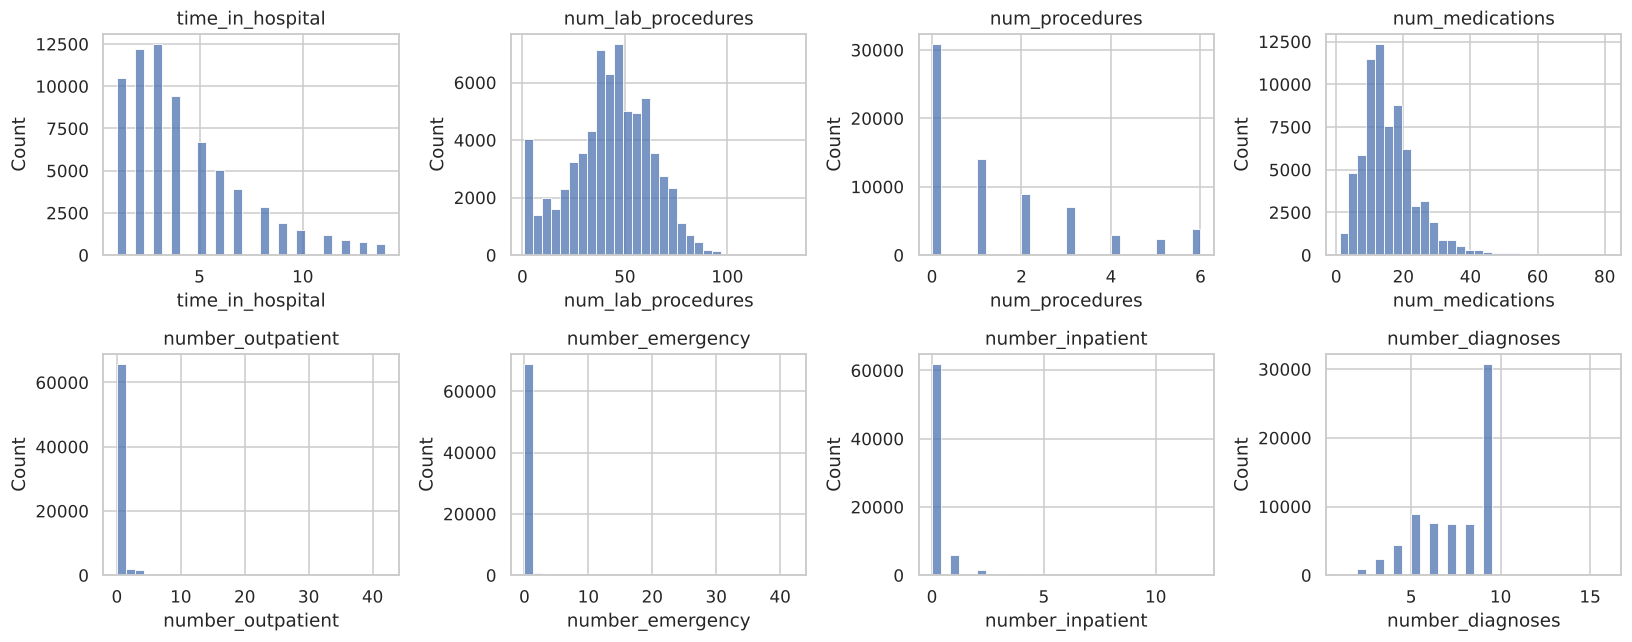

In [7]:
num = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
       "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
print(df[num].describe().T.round(2).to_string())
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), num):
    sns.histplot(df[c], ax=ax, bins=30, color="#4c72b0")
    ax.set_title(c)
fig.tight_layout()
fig.savefig(FIG + "eda_numericas.png", dpi=130)

Las variables de utilización previa (`number_outpatient`, `number_emergency`, `number_inpatient`)
tienen cola larga: los árboles lo manejan bien; para la regresión logística se estandarizan.

## 7. Tasa de reingreso <30 según variables clave (crosstabs)

In [8]:
def rate(col, order=None):
    t = df.groupby(col)["target"].agg(["mean", "size"]).rename(columns={"mean": "tasa_<30", "size": "n"})
    t["tasa_<30"] = (t["tasa_<30"] * 100).round(2)
    return t.loc[order] if order else t.sort_values("tasa_<30", ascending=False)

print(rate("age", sorted(df["age"].unique())).to_string())
print()
print(rate("number_inpatient").head(10).to_string())

          tasa_<30      n
age                      
[0-10)        1.96    153
[10-20)       4.87    534
[20-30)       7.40   1121
[30-40)       6.98   2692
[40-50)       7.41   6828
[50-60)       7.12  12349
[60-70)       9.00  15684
[70-80)      10.24  17750
[80-90)      10.76  11102
[90-100)      9.55   1760

                  tasa_<30    n
number_inpatient               
12                  100.00    2
10                   80.00    5
11                   50.00    2
7                    47.37   19
9                    42.86    7
6                    40.00   55
5                    28.43  102
3                    23.76  463
4                    23.68  228
8                    23.08   13

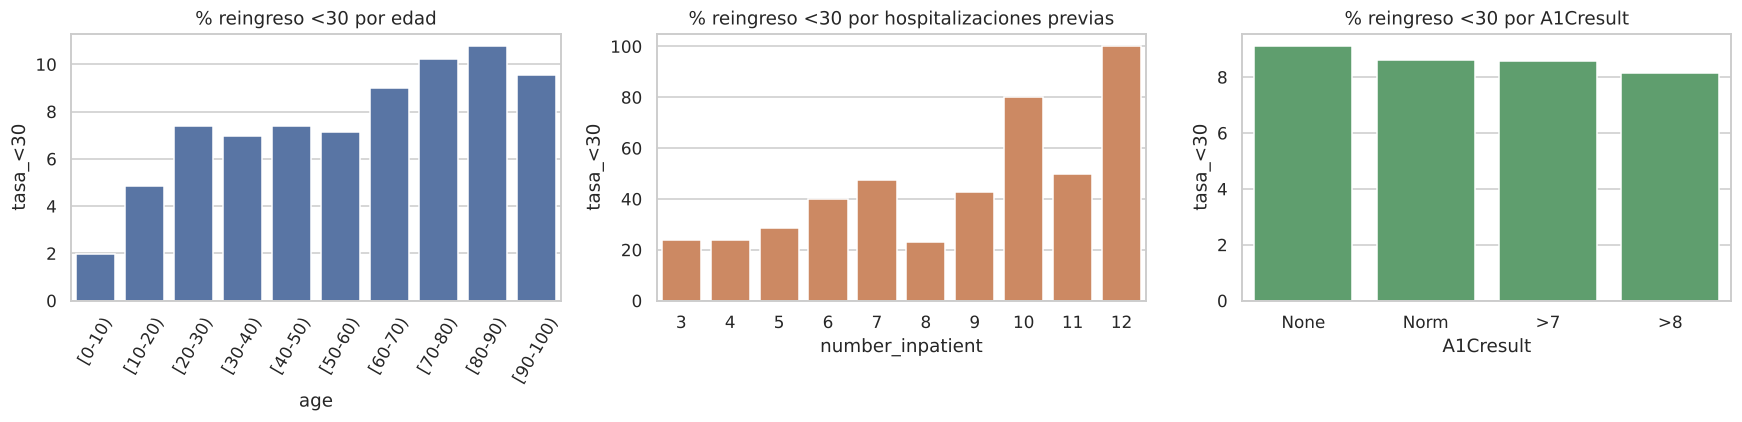

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
a = rate("age", sorted(df["age"].unique()))
sns.barplot(x=a.index, y=a["tasa_<30"], ax=axes[0], color="#4c72b0")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_title("% reingreso <30 por edad")
b = rate("number_inpatient").loc[:8].sort_index()
sns.barplot(x=b.index.astype(str), y=b["tasa_<30"], ax=axes[1], color="#dd8452")
axes[1].set_title("% reingreso <30 por hospitalizaciones previas")
axes[1].set_xlabel("number_inpatient")
c = rate("A1Cresult")
sns.barplot(x=c.index, y=c["tasa_<30"], ax=axes[2], color="#55a868")
axes[2].set_title("% reingreso <30 por A1Cresult")
fig.tight_layout()
fig.savefig(FIG + "eda_tasas.png", dpi=130)

**Hallazgos:** el reingreso <30 sube con las **hospitalizaciones previas** (`number_inpatient`;
con 3+ previas supera el 20 %) y con la edad hasta los 80-90 años (de ~7 % a ~11 %). Las
diferencias por `A1Cresult` son pequeñas (8.2-9.1 %), pero el valor `None` (no medido, ~82 % de
los casos) tiene la tasa más alta, así que se conserva como categoría propia en lugar de imputarse.

In [10]:
print(rate("discharge_disposition_id").head(8).to_string())
print()
print(rate("insulin").to_string())
print()
print(rate("diabetesMed").to_string())

                          tasa_<30     n
discharge_disposition_id                
12                           50.00     2
15                           45.00    40
28                           35.56    90
22                           26.31  1410
9                            22.22     9
5                            20.59   913
2                            13.78  1539
3                            13.39  8784

         tasa_<30      n
insulin                 
Down        10.55   7321
Up           9.84   6777
Steady       9.26  21617
No           8.28  34258

             tasa_<30      n
diabetesMed                 
Yes              9.42  53293
No               7.55  16680

## 8. Conclusiones para el preprocesamiento (→ notebook 02)
1. Primer encuentro por paciente + excluir fallecimiento/hospicio → ~69 973 filas.
2. Target binario con ~9 % de positivos → métricas robustas al desbalance + `class_weight`.
3. `weight`, `payer_code`, ids y constantes (`examide`, `citoglipton`) fuera.
4. `admission_type_id`, `discharge_disposition_id`, `admission_source_id` son **categorías**.
5. `diag_1/2/3` (cientos de códigos ICD-9) → 8 grupos clínicos + `Other` + `Missing`.
6. Imputación y encoding **dentro de un `Pipeline`**, tras el split.